In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
from pathlib import Path

ROOT = Path("..")                                  # racine du projet, vue depuis notebooks/
meta = pd.read_csv(ROOT / "data/metadata.csv")
train = meta[meta["split"] == "train"]             # on explore UNIQUEMENT le train
print(len(train), "clips en train")

3361 clips en train


In [2]:
clip = train.iloc[0]
y, sr = librosa.load(ROOT / clip["wav_path"], sr=16000)   # y = le signal, sr = 16 000
print("Locuteur :", clip["speaker_id"])
print("Échantillons :", len(y), "| Durée :", round(len(y) / sr, 2), "s")
print("10 premières valeurs :", np.round(y[:10], 4))

c:\Projets\VoicePrint_Piscine\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Locuteur : cv_025
Échantillons : 59328 | Durée : 3.71 s
10 premières valeurs : [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


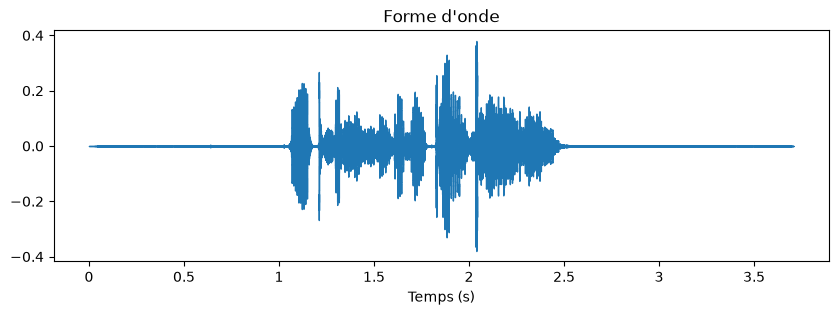

In [3]:
plt.figure(figsize=(10, 3))
librosa.display.waveshow(y, sr=sr)
plt.title("Forme d'onde")
plt.xlabel("Temps (s)")
plt.show()

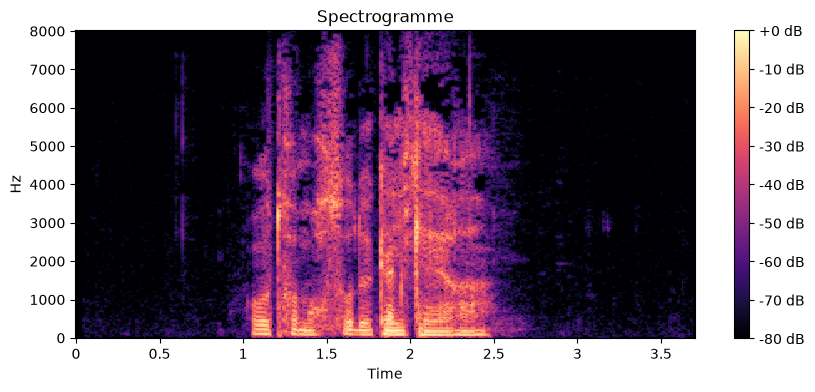

In [4]:
N_FFT, HOP = 512, 160        # tranches de 32 ms, décalées de 10 ms
S = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP))
S_db = librosa.amplitude_to_db(S, ref=np.max)   # en décibels, comme l'oreille

plt.figure(figsize=(10, 4))
librosa.display.specshow(S_db, sr=sr, hop_length=HOP, x_axis="time", y_axis="hz")
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogramme")
plt.show()

Forme : (20, 371) → 20 coefficients x 371 tranches de temps


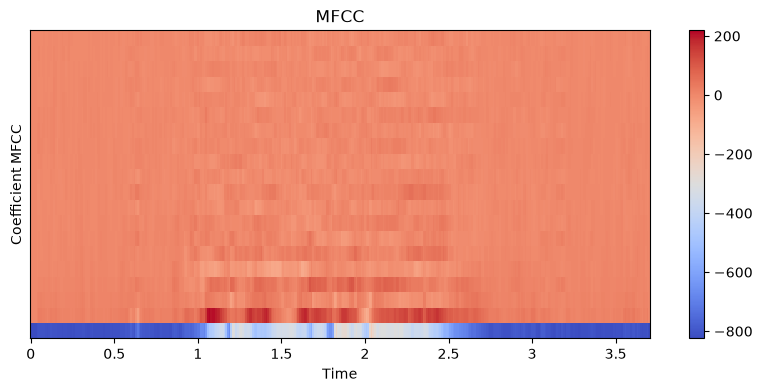

In [5]:
mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20, n_fft=N_FFT, hop_length=HOP)
print("Forme :", mfcc.shape, "→ 20 coefficients x", mfcc.shape[1], "tranches de temps")

plt.figure(figsize=(10, 4))
librosa.display.specshow(mfcc, sr=sr, hop_length=HOP, x_axis="time")
plt.colorbar()
plt.ylabel("Coefficient MFCC")
plt.title("MFCC")
plt.show()

In [6]:
vec = np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)])
print("Taille :", vec.shape)
print(np.round(vec, 1))

Taille : (40,)
[-6.337e+02  5.680e+01  6.500e+00  2.300e+01 -1.070e+01  9.100e+00
  2.000e-01  2.900e+00 -4.000e+00  3.000e+00 -1.800e+00 -3.200e+00
 -0.000e+00 -2.600e+00  1.200e+00 -3.900e+00 -2.200e+00 -2.600e+00
 -2.800e+00 -1.900e+00  2.060e+02  5.830e+01  1.770e+01  2.540e+01
  2.280e+01  1.520e+01  1.240e+01  1.140e+01  9.800e+00  1.340e+01
  7.600e+00  9.000e+00  7.400e+00  7.700e+00  8.000e+00  9.300e+00
  8.400e+00  8.200e+00  7.100e+00  7.300e+00]


In [7]:
def vecteur(chemin):
    y, sr = librosa.load(ROOT / chemin, sr=16000)
    m = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20, n_fft=N_FFT, hop_length=HOP)
    return np.concatenate([m.mean(axis=1), m.std(axis=1)])

def cosinus(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

locs = train["speaker_id"].unique()
A = train[train["speaker_id"] == locs[0]]["wav_path"].tolist()
B = train[train["speaker_id"] == locs[1]]["wav_path"].tolist()

print("Même personne       :", round(cosinus(vecteur(A[0]), vecteur(A[1])), 4))
print("Personnes différentes:", round(cosinus(vecteur(A[0]), vecteur(B[0])), 4))

Même personne       : 0.9935
Personnes différentes: 0.9922
